In [2]:
import time, random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, models,transforms
from torch.utils.data import DataLoader
import torchvision.transforms.v2 as v2
from tqdm.auto import tqdm

try:
    import wandb
except ImportError:
    wandb = None

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
DATA_DIR = "./dataset"
OUT_DIR = Path("./simclr_outputs")
OUT_DIR.mkdir(exist_ok=True, parents=True)

USE_WANDB = True
WANDB_PROJECT = "simclr-cifar10-ablations_3"
WANDB_ENTITY = "shriramgolla-iit-hyderabad"
2
EPOCHS = 100
BATCH_SIZES = [ 128, 256,512,1024,2048]
PROBE_EPOCHS = 10
NUM_WORKERS = 2
BASE_LR = 0.3
WEIGHT_DECAY = 1e-4
TEMPERATURE = 0.5
PROJECTION_DIM = 128
PROJECTION_HIDDEN = 512
PROBE_INTERVAL = 20  # Evaluate every 20 SimCLR epochs
PROBE_EPOCHS = 10    # Train the linear classifier for 10 epochs per evaluation
LOG_EVERY = 50

print("Device:", DEVICE)

Device: cuda


In [4]:
DATA_DIR = './dataset'

In [9]:

from kaggle_secrets import UserSecretsClient
wandb.login(key=UserSecretsClient().get_secret("WANDB_API_KEY"))
USE_WANDB = True

/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: shriramgolla (shriramgolla-iit-hyderabad) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


## 2. Augmentations and data

In [10]:
!wget -P ./dataset/  https://data.brainchip.com/dataset-mirror/cifar10/cifar-10-python.tar.gz
!tar -xzf ./dataset/cifar-10-python.tar.gz -C ./dataset/
import tarfile
DATA_DIR = './dataset'
with tarfile.open('./dataset/cifar-10-python.tar.gz') as tf:
     tf.extractall(DATA_DIR)
     _found = [DATA_DIR]   # skip download
print("DATA_DIR:", DATA_DIR, "| using local files:", bool(_found))

--2026-10-27 13:36:15--  https://data.brainchip.com/dataset-mirror/cifar10/cifar-10-python.tar.gz
Resolving data.brainchip.com (data.brainchip.com)... 146.59.209.152, 2001:41d0:301::31
Connecting to data.brainchip.com (data.brainchip.com)|146.59.209.152|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 170498071 (163M) [application/x-gzip]
Saving to: ‘./dataset/cifar-10-python.tar.gz’

cifar-10-python.tar 100%[===================>] 162.60M  26.3MB/s    in 7.5s    

2026-10-27 13:36:23 (21.8 MB/s) - ‘./dataset/cifar-10-python.tar.gz’ saved [170498071/170498071]



/tmp/ipykernel_49/3416165223.py:6: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tf.extractall(DATA_DIR)


DATA_DIR: ./dataset | using local files: True


In [11]:
MEAN = (0.4914, 0.4822, 0.4465)
STD = (0.2470, 0.2435, 0.2616)

def make_gpu_transform(color=True, blur=True):
    # These v2 transforms will run directly on batched GPU tensors
    ops = [
        v2.RandomResizedCrop(32, scale=(0.08, 1.0), antialias=True),
        v2.RandomHorizontalFlip(),
    ]
    if color:
        ops += [
            v2.RandomApply([v2.ColorJitter(0.8, 0.8, 0.8, 0.2)], p=0.8),
            v2.RandomGrayscale(p=0.2),
        ]
    if blur:
        ops += [v2.RandomApply([v2.GaussianBlur(3, sigma=(0.1, 2.0))], p=0.5)]

    return v2.Compose([
        *ops,
        v2.Normalize(MEAN, STD)
    ])

def make_pretrain_loader(cfg):
    # Lightweight CPU loading: just load image and convert to float32 tensor
    base_tf = v2.Compose([
        v2.ToImage(),
        v2.ToDtype(torch.float32, scale=True)
    ])

    ds = datasets.CIFAR10(
        DATA_DIR, train=True,
        transform=base_tf,download =False
    )
    return DataLoader(
        ds, batch_size=cfg["batch_size"], shuffle=True, drop_last=True,
        num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda"), persistent_workers=True
    )

## 3. Modified ResNet-18 and SimCLR loss

In [12]:
def make_encoder():
    model = models.resnet18(weights=None)
    model.layer4[0] = nn.Conv2d(
        256, 512, kernel_size=3, stride=1, padding=1, bias=False
    )
    model.fc = nn.Identity()
    return model

class SimCLR(nn.Module):
    def __init__(self, projection=True):
        super().__init__()
        self.encoder = make_encoder()
        self.projector = (
            nn.Sequential(
                nn.Linear(512, PROJECTION_HIDDEN, bias=False),
                nn.BatchNorm1d(PROJECTION_HIDDEN),
                nn.ReLU(inplace=True),
                nn.Linear(PROJECTION_HIDDEN, PROJECTION_DIM),
            ) if projection else nn.Identity()
        )
    def forward(self, x):
        h = self.encoder(x)
        return h, self.projector(h)

def nt_xent(z1, z2, temperature):
    n = z1.size(0)
    z = F.normalize(torch.cat([z1, z2]), dim=1)
    logits = z @ z.T / temperature
    logits.fill_diagonal_(float("-inf"))
    targets = torch.cat([
        torch.arange(n, 2*n, device=z.device),
        torch.arange(0, n, device=z.device),
    ])
    return F.cross_entropy(logits, targets)

## 4. SimCLR training

In [13]:
def train_simclr(name, cfg):
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)

    if DEVICE.type == "cuda":
        torch.cuda.manual_seed_all(SEED)

    loader = make_pretrain_loader(cfg)
    model = SimCLR(cfg["projection"]).to(DEVICE)

    # Initialize the GPU transformation pipeline
    gpu_transform = make_gpu_transform(cfg["color"], cfg["blur"])

    # Kept adaptive learning rate based on linear scaling rule
    lr = BASE_LR * cfg["batch_size"] / 256

    optimizer = torch.optim.SGD(
        model.parameters(), lr=lr,
        momentum=0.9, weight_decay=WEIGHT_DECAY
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=EPOCHS
    )

    run = None
    if USE_WANDB and wandb is not None:
        run = wandb.init(
            project=WANDB_PROJECT,
            entity=WANDB_ENTITY,
            name=name,
            config={
                **cfg,
                "epochs": EPOCHS,
                "effective_lr": lr,
                "backbone": "modified_resnet18",
            },
            job_type="pretraining",
            reinit=True,
        )

    history = []
    start = time.perf_counter()

    try:
        for epoch in range(EPOCHS):
            model.train()
            loss_sum, seen = 0.0, 0

            # Loader now yields a single image batch
            for x, _ in tqdm(
                loader,
                desc=f"{name} {epoch+1}/{EPOCHS}",
                leave=False,
            ):
                x = x.to(DEVICE, non_blocking=True)

                # Generate views efficiently on the GPU
                x1 = gpu_transform(x)
                x2 = gpu_transform(x)

                optimizer.zero_grad(set_to_none=True)

                # Standard FP32 forward pass
                _, z1 = model(x1)
                _, z2 = model(x2)

                loss = nt_xent(
                    z1, z2,
                    cfg["temperature"],
                )

                # Standard FP32 backward pass without GradScaler
                loss.backward()
                optimizer.step()

                loss_sum += loss.detach().item() * x.size(0)
                seen += x.size(0)

            scheduler.step()

            epoch_loss = loss_sum / max(seen, 1)
            history.append({
                "epoch": epoch + 1,
                "train_loss": epoch_loss,
            })

            if run:
                run.log({
                    "epoch": epoch + 1,
                    "pretrain/loss": epoch_loss,
                })

            print(
                f"{name} {epoch+1}/{EPOCHS}: "
                f"loss={epoch_loss:.4f}"
            )

        if DEVICE.type == "cuda":
            torch.cuda.synchronize()

        total_seconds = time.perf_counter() - start
        hist = pd.DataFrame(history)

        hist.to_csv(
            OUT_DIR / f"{name}_pretrain.csv",
            index=False,
        )

        torch.save({
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "config": cfg,
            "history": history,
            "total_training_seconds": total_seconds,
        }, OUT_DIR / f"{name}.pt")

        if run:
            run.summary["total_training_time_seconds"] = total_seconds
            run.summary["final_train_loss"] = hist["train_loss"].iloc[-1]
            run.finish()
            run = None

        print(
            f"{name}: total training time = "
            f"{total_seconds / 60:.2f} minutes"
        )

        return model, hist, {
            "run": name,
            "batch_size": cfg["batch_size"],
            "final_train_loss": hist["train_loss"].iloc[-1],
            "total_training_seconds": total_seconds,
        }

    finally:
        if run is not None:
            run.finish()

## 5. Frozen-encoder linear probe

In [54]:
def make_probe_loaders():
    train_tf = transforms.v2.Compose([
        transforms.v2.RandomCrop(32, padding=4),
        transforms.v2.RandomHorizontalFlip(),
        transforms.v2.ToTensor(), transforms.v2.Normalize(MEAN, STD)
    ])
    test_tf = transforms.v2.Compose([
        transforms.v2.ToTensor(), transforms.v2.Normalize(MEAN, STD)
    ])
    train_ds = datasets.CIFAR10(DATA_DIR, train=True, download=False, transform=train_tf)
    test_ds = datasets.CIFAR10(DATA_DIR, train=False, download=False, transform=test_tf)
    train_loader = DataLoader(train_ds, batch_size=256, shuffle=True, num_workers=NUM_WORKERS,persistent_workers=True)
    test_loader = DataLoader(test_ds, batch_size=512, shuffle=False, num_workers=NUM_WORKERS,persistent_workers=True)
    return train_loader, test_loader

@torch.no_grad()
def test_top1(encoder, classifier, loader):
    encoder.eval()
    classifier.eval()
    correct, total = 0, 0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        pred = classifier(encoder(x)).argmax(1)
        correct += (pred == y).sum().item()
        total += y.size(0)
    return 100 * correct / total

def linear_probe(name, encoder):
    # Freeze encoder; only classifier weights are updated.
    encoder.to(DEVICE).eval()
    for p in encoder.parameters():
        p.requires_grad = False

    train_loader, test_loader = make_probe_loaders()
    classifier = nn.Linear(512, 10).to(DEVICE)
    optimizer = torch.optim.SGD(classifier.parameters(), lr=0.1, momentum=0.9)
    history = []
    start = time.perf_counter()

    for epoch in range(PROBE_EPOCHS):
        classifier.train()
        loss_sum, correct, total = 0.0, 0, 0
        for x, y in tqdm(train_loader, desc=f"Probe {name} {epoch+1}/{PROBE_EPOCHS}", leave=False):
            x, y = x.to(DEVICE), y.to(DEVICE)
            with torch.no_grad():
                features = encoder(x)
            optimizer.zero_grad()
            logits = classifier(features)
            loss = F.cross_entropy(logits, y)
            loss.backward()
            optimizer.step()
            loss_sum += loss.item() * y.size(0)
            correct += (logits.argmax(1) == y).sum().item()
            total += y.size(0)

        test_acc = test_top1(encoder, classifier, test_loader)
        row = {
            "probe_epoch": epoch + 1,
            "probe_train_loss": loss_sum / total,
            "probe_train_top1": 100 * correct / total,
            "test_top1_accuracy": test_acc,
        }
        history.append(row)
        print(f"{name} probe {epoch+1}/{PROBE_EPOCHS}: test top-1={test_acc:.2f}%")

    probe_seconds = time.perf_counter() - start
    hist = pd.DataFrame(history)
    hist.to_csv(OUT_DIR / f"{name}_linear_probe.csv", index=False)
    torch.save({"classifier_state_dict": classifier.state_dict(), "history": history},
               OUT_DIR / f"{name}_linear_classifier.pt")
    return hist, probe_seconds

## 6. Define and run all ablations

In [15]:
experiments = []

# Batch-size ablation: all SimCLR components enabled.
for batch_size in BATCH_SIZES:
    experiments.append((f"batch_{batch_size}", {
        "batch_size": batch_size, "temperature": TEMPERATURE,
        "projection": True, "color": True, "blur": True,
    }))

# Method ablations, all at batch size 256.
for name, changes in [
    ("baseline", {}),
    ("no_color", {"color": False}),
    ("no_blur", {"blur": False}),
    ("no_projection", {"projection": False}),
    ("temperature_0.1", {"temperature": 0.1}),
]:
    cfg = {
        "batch_size": 256, "temperature": TEMPERATURE,
        "projection": True, "color": True, "blur": True,
    }
    cfg.update(changes)
    experiments.append((name, cfg))

histories, probe_histories, summaries = {}, {}, []

for name, cfg in experiments:
    print("\n" + "=" * 60 + "\nRunning:", name)
    model, hist, summary = train_simclr(name, cfg)
    histories[name] = hist

    probe_hist, probe_seconds = linear_probe(name, model.encoder)
    probe_histories[name] = probe_hist
    summary.update({
        "final_test_top1_accuracy": probe_hist.test_top1_accuracy.iloc[-1],
    })
    summaries.append(summary)

    if USE_WANDB and wandb is not None:
        with wandb.init(
            project=WANDB_PROJECT, entity=WANDB_ENTITY,
            name=f"{name}-linear-probe", job_type="linear-probe", reinit=True,
            config={"source_run": name, "probe_epochs": PROBE_EPOCHS, "encoder_frozen": True}
        ) as run:
            for row in probe_hist.to_dict("records"):
                run.log({
                    "probe/epoch": row["probe_epoch"],
                    "probe/test_top1_accuracy": row["test_top1_accuracy"],
                }, step=row["probe_epoch"])
            run.summary["final_test_top1_accuracy"] = summary["final_test_top1_accuracy"]

    del model
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

summary_df = pd.DataFrame(summaries)
summary_df.to_csv(OUT_DIR / "experiment_summary.csv", index=False)
display(summary_df)


Running: batch_128


wandb: WARNING Using a boolean value for 'reinit' is deprecated. Use 'return_previous' or 'finish_previous' instead.


batch_128 1/100:   0%|          | 0/390 [00:00<?, ?it/s]

batch_128 1/100: loss=4.7167


batch_128 2/100:   0%|          | 0/390 [00:00<?, ?it/s]

...

no_projection 28/100:   0%|          | 0/195 [00:00<?, ?it/s]

no_projection 28/100: loss=5.1420


no_projection 29/100:   0%|          | 0/195 [00:00<?, ?it/s]

epoch,▁▁▂▂▂▂▃▃▃▃▄▄▄▄▅▅▅▅▆▆▆▆▇▇▇▇██
pretrain/loss,█▅▅▅▄▃▃▃▃▃▂▃▂▂▂▂▂▂▂▂▂▂▂▂▁▂▁▁
epoch,28
pretrain/loss,5.14203


KeyboardInterrupt: 

In [16]:
summary_df = pd.DataFrame(summaries)
summary_df.to_csv(OUT_DIR / "experiment_summary.csv", index=False)
display(summary_df)

,run,batch_size,final_train_loss,total_training_seconds,final_test_top1_accuracy
0,batch_128,128,4.006198,1964.832048,49.16
1,batch_256,256,4.734557,1704.015629,48.92
2,batch_512,512,5.443672,1606.413998,46.88
3,batch_1024,1024,6.189275,1588.415959,32.14
4,batch_2048,2048,7.071606,1671.470301,22.68
5,baseline,256,4.734483,1698.730723,49.53
6,no_color,256,4.454080,1656.363189,42.13
7,no_blur,256,4.703035,1691.464229,47.11


## 7. Plots and W&B summary table

/tmp/ipykernel_49/549519148.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=8)


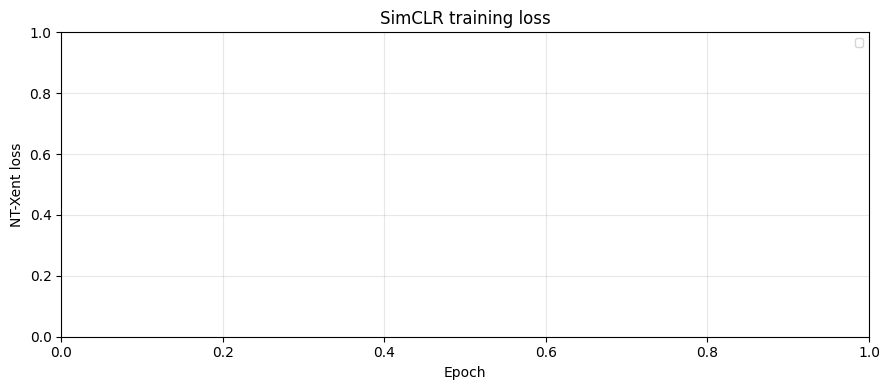

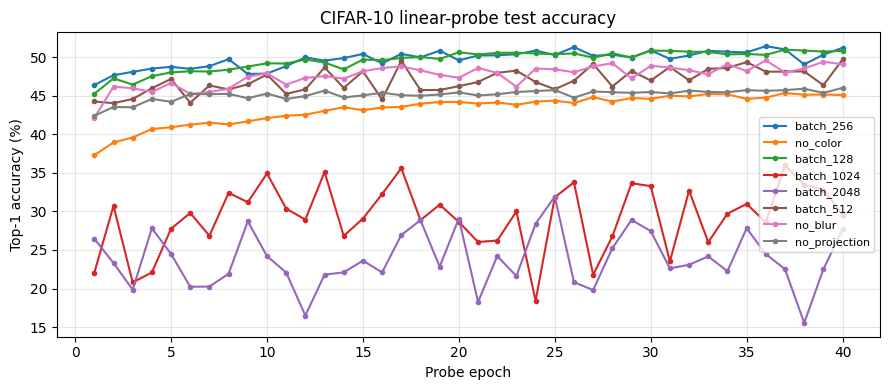

,run,batch_size,final_train_loss,total_training_seconds,final_test_top1_accuracy
0,batch_128,128,4.006198,1964.832048,49.16
1,batch_256,256,4.734557,1704.015629,48.92
2,batch_512,512,5.443672,1606.413998,46.88
3,batch_1024,1024,6.189275,1588.415959,32.14
4,batch_2048,2048,7.071606,1671.470301,22.68
5,baseline,256,4.734483,1698.730723,49.53
6,no_color,256,4.454080,1656.363189,42.13
7,no_blur,256,4.703035,1691.464229,47.11


In [62]:
# Plot training loss.
fig, ax = plt.subplots(figsize=(9, 4))
for name, hist in histories.items():
    ax.plot(hist.epoch, hist.train_loss, label=name)
ax.set(title="SimCLR training loss", xlabel="Epoch", ylabel="NT-Xent loss")
ax.grid(True, alpha=0.3)
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUT_DIR / "training_loss.png", dpi=150)
plt.show()

# Plot linear-probe test accuracy.
fig, ax = plt.subplots(figsize=(9, 4))
for name, hist in probe_histories.items():
    ax.plot(hist.probe_epoch, hist.test_top1_accuracy, marker=".", label=name)
ax.set(title="CIFAR-10 linear-probe test accuracy", xlabel="Probe epoch", ylabel="Top-1 accuracy (%)")
ax.grid(True, alpha=0.3)
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUT_DIR / "linear_probe_accuracy.png", dpi=150)
plt.show()

# Minimal comparison table: accuracy and pretraining time.
display(summary_df[["run", "batch_size", "final_train_loss",
                    "total_training_seconds", "final_test_top1_accuracy"]])

if USE_WANDB and wandb is not None:
    with wandb.init(project=WANDB_PROJECT, entity=WANDB_ENTITY,
                    name="ablation-summary", job_type="summary", reinit=True) as run:
        run.log({
            "results/summary_table": wandb.Table(dataframe=summary_df[[
                "run", "batch_size", "final_train_loss",
                "total_training_seconds", "final_test_top1_accuracy"
            ]]),
            "plots/training_loss": wandb.Image(str(OUT_DIR / "training_loss.png")),
            "plots/linear_probe_accuracy": wandb.Image(str(OUT_DIR / "linear_probe_accuracy.png")),
        })

In [ ]:
PROBE_EPOCHS = 100

In [45]:
for name, cfg in experiments[-2:]:
    print("\n" + "=" * 60 + "\nRunning:", name)
    model, hist, summary = train_simclr(name, cfg)
    histories[name] = hist

    probe_hist, probe_seconds = linear_probe(name, model.encoder)
    probe_histories[name] = probe_hist
    summary.update({
        "final_test_top1_accuracy": probe_hist.test_top1_accuracy.iloc[-1],
    })
    summaries.append(summary)

    if USE_WANDB and wandb is not None:
        with wandb.init(
            project=WANDB_PROJECT, entity=WANDB_ENTITY,
            name=f"{name}-linear-probe", job_type="linear-probe", reinit=True,
            config={"source_run": name, "probe_epochs": 100, "encoder_frozen": True}
        ) as run:
            for row in probe_hist.to_dict("records"):
                run.log({
                    "probe/epoch": row["probe_epoch"],
                    "probe/test_top1_accuracy": row["test_top1_accuracy"],
                }, step=row["probe_epoch"])
            run.summary["final_test_top1_accuracy"] = summary["final_test_top1_accuracy"]

    del model
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

summary_df = pd.DataFrame(summaries)
summary_df.to_csv(OUT_DIR / "experiment_summary.csv", index=False)
display(summary_df)


Running: no_projection


no_projection 1/100:   0%|          | 0/195 [00:00<?, ?it/s]

no_projection 1/100: loss=5.6281


no_projection 2/100:   0%|          | 0/195 [00:00<?, ?it/s]

no_projection 2/100: loss=5.4457


...

no_projection 100/100:   0%|          | 0/195 [00:00<?, ?it/s]

no_projection 100/100: loss=4.8328


epoch,▁▁▁▁▁▂▂▂▂▂▃▃▃▃▃▄▄▄▄▄▅▅▅▅▅▆▆▆▆▆▇▇▇▇▇▇████
pretrain/loss,█▆▆▅▆▆▆▆▅▅▅▅▅▄▄▅▄▄▄▄▃▃▃▃▃▃▃▃▃▂▂▂▂▂▂▁▂▁▁▁
epoch,100
final_train_loss,4.83275
pretrain/loss,4.83275
total_training_time_seconds,1683.52433


no_projection: total training time = 28.06 minutes


TypeError: make_probe_loaders() missing 1 required positional argument: 'batch_size'

In [46]:
checkpoint_files = list(OUT_DIR.glob("*.pt"))
checkpoint_files = [f for f in checkpoint_files if "classifier" not in f.name]

In [47]:
checkpoint_files

[PosixPath('simclr_outputs/batch_256.pt'),
 PosixPath('simclr_outputs/no_color.pt'),
 PosixPath('simclr_outputs/batch_128.pt'),
 PosixPath('simclr_outputs/batch_1024.pt'),
 PosixPath('simclr_outputs/batch_2048.pt'),
 PosixPath('simclr_outputs/batch_512.pt'),
 PosixPath('simclr_outputs/no_blur.pt'),
 PosixPath('simclr_outputs/no_projection.pt'),
 PosixPath('simclr_outputs/baseline.pt')]

In [48]:
bs = [256,256,128,1024,2048,512,256,256,256]
bdict = {}

for (i,ckp) in enumerate(checkpoint_files):
    bdict[ckp.stem] = bs[i]

In [49]:
bdict

{'batch_256': 256,
 'no_color': 256,
 'batch_128': 128,
 'batch_1024': 1024,
 'batch_2048': 2048,
 'batch_512': 512,
 'no_blur': 256,
 'no_projection': 256,
 'baseline': 256}

In [53]:
PROBE_EPOCHS = 40

In [ ]:
PROBE_EPOCHS = 40
PROBE_BATCH_SIZE = 256

histories, probe_histories, summaries = {}, {}, []

def make_probe_loaders(batch_size):
    # Ensure download=True so it automatically handles the .tar.gz extraction
    train_tf = v2.Compose([
        v2.ToImage(),
        v2.ToDtype(torch.float32, scale=True),
        v2.RandomCrop(32, padding=4),
        v2.RandomHorizontalFlip(),
        v2.Normalize(MEAN, STD)
    ])
    test_tf = v2.Compose([
        v2.ToImage(),
        v2.ToDtype(torch.float32, scale=True),
        v2.Normalize(MEAN, STD)
    ])
    
    # Fixed: val=True is invalid for CIFAR10; it must be train=True
    train_ds = datasets.CIFAR10(DATA_DIR, train=True, download=False, transform=train_tf)
    test_ds = datasets.CIFAR10(DATA_DIR, train=False, download=False, transform=test_tf)
    
    train_loader = DataLoader(
        train_ds, batch_size=batch_size, shuffle=True, 
        num_workers=2, persistent_workers=True, pin_memory=True, prefetch_factor=4
    )
    test_loader = DataLoader(
        test_ds, batch_size=batch_size * 2, shuffle=False, 
        num_workers=2, persistent_workers=True, pin_memory=True, prefetch_factor=4
    )
    return train_loader, test_loader

@torch.inference_mode()
def test_top1(encoder, classifier, loader):
    encoder.eval()
    classifier.eval()
    correct, total = 0, 0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        # Apply channels_last if using it
        if DEVICE.type == "cuda":
            x = x.contiguous(memory_format=torch.channels_last)
            
        pred = classifier(encoder(x)).argmax(1)
        correct += (pred == y).sum().item()
        total += y.size(0)
    return 100 * correct / total

def linear_probe(name, encoder, probe_lr, train_loader, test_loader):
    encoder.to(DEVICE).eval()
    for p in encoder.parameters():
        p.requires_grad = False

    classifier = nn.Linear(512, 10).to(DEVICE)
    optimizer = torch.optim.SGD(classifier.parameters(), lr=probe_lr, momentum=0.9)
    history = []
    start = time.perf_counter()

    for epoch in range(PROBE_EPOCHS):
        classifier.train()
        loss_sum, correct, total = 0.0, 0, 0
        for x, y in tqdm(train_loader, desc=f"Probe {name} {epoch+1}/{PROBE_EPOCHS}", leave=False):
            x, y = x.to(DEVICE), y.to(DEVICE)
            if DEVICE.type == "cuda":
                x = x.contiguous(memory_format=torch.channels_last)
                
            with torch.no_grad():
                features = encoder(x)
                
            optimizer.zero_grad(set_to_none=True)
            logits = classifier(features)
            loss = F.cross_entropy(logits, y)
            loss.backward()
            optimizer.step()
            
            loss_sum += loss.item() * y.size(0)
            correct += (logits.argmax(1) == y).sum().item()
            total += y.size(0)

        test_acc = test_top1(encoder, classifier, test_loader)
        row = {
            "probe_epoch": epoch + 1,
            "probe_train_loss": loss_sum / total,
            "probe_train_top1": 100 * correct / total,
            "test_top1_accuracy": test_acc,
        }
        history.append(row)
        print(f"{name} probe {epoch+1}/{PROBE_EPOCHS}: test top-1={test_acc:.2f}%")

    probe_seconds = time.perf_counter() - start
    hist = pd.DataFrame(history)
    hist.to_csv(OUT_DIR / f"{name}_extended_linear_probe.csv", index=False)
    torch.save({"classifier_state_dict": classifier.state_dict(), "history": history},
               OUT_DIR / f"{name}_extended_linear_classifier.pt")
    return hist, probe_seconds


def evaluate_saved_models():
    train_loader, test_loader = make_probe_loaders(PROBE_BATCH_SIZE)
    
    # Find all saved checkpoints in the output directory
    checkpoint_files = list(OUT_DIR.glob("*.pt"))
    
    # Filter out classifier checkpoints if any exist from previous runs
    checkpoint_files = [f for f in checkpoint_files if "classifier" not in f.name]
    
    for ckpt_path in checkpoint_files:
        name = ckpt_path.stem
        
        # 1. Load the saved checkpoint and config first
        checkpoint = torch.load(ckpt_path, map_location=DEVICE, weights_only=False)
        cfg = checkpoint["config"]
        
        # Retrieve pretraining batch size dynamically instead of using manual bdict
        pretrain_batch_size = cfg.get("batch_size", 256)
        probe_lr = 0.1 * (pretrain_batch_size / 256.0)
        
        print(f"\n{'='*60}\nEvaluating Model: {name} | Pretrain BS: {pretrain_batch_size} | Probe LR: {probe_lr:.4f}")
        
        model = SimCLR(projection=cfg.get("projection", True)).to(DEVICE)
        model.load_state_dict(checkpoint["model_state_dict"])
        
        if DEVICE.type == "cuda":
            model = model.to(memory_format=torch.channels_last)
            
        probe_hist, probe_seconds = linear_probe(name, model.encoder.eval(), probe_lr, train_loader, test_loader)
        probe_histories[name] = probe_hist
        
        # Initialize summary dict for this specific run
        summary = {
            "run": name,
            "final_test_top1_accuracy": probe_hist["test_top1_accuracy"].iloc[-1],
            "probe_time_seconds": probe_seconds
        }
        summaries.append(summary)
    
        if USE_WANDB and wandb is not None:
            with wandb.init(
                project=WANDB_PROJECT, entity=WANDB_ENTITY,
                name=f"{name}-linear-probe", job_type="linear-probe", reinit=True,
                config={"source_run": name, "probe_epochs": PROBE_EPOCHS, "encoder_frozen": True, "probe_lr": probe_lr}
            ) as run:
                for row in probe_hist.to_dict("records"):
                    run.log({
                        "probe/epoch": row["probe_epoch"],
                        "probe/test_top1_accuracy": row["test_top1_accuracy"],
                    }, step=row["probe_epoch"])
                run.summary["final_test_top1_accuracy"] = summary["final_test_top1_accuracy"]
    
        del model
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()

# Execute the evaluation routine
evaluate_saved_models()